# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** \
Запуск проводился в Colab на Tesla T4. \
Основная выбранная модель: https://huggingface.co/google-bert/bert-base-cased (Apache 2.0 лицензия)\
Датасеты:
- https://github.com/mooselab/SDLog (разметка конфиденциальной/чувствительной информации в логах); MIT лицензия
- https://github.com/logpai/loghub (соответствующие логи с метаданными); лицензия разрешает учебное и исследовательское использование

Бонусы: 6.2, 6.3, 6.4, 6.5 \
Нерешенные задачи: 6.1

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

In [5]:
BONUS_TASKS.update({"6.2", "6.3", "6.4", "6.5"})


---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [6]:
MODEL_ID = 'google-bert/bert-base-cased'   # ваш код: id модели на Hugging Face Hub
REVISION = 'cd5ef92a9fb2f889e972770a36d4ed042daf221e'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {"use_fast": True}   # для roberta-base: {'add_prefix_space': True}

In [7]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    google-bert/bert-base-cased
revision: cd5ef92a9fb2f889e972770a36d4ed042daf221e
license:  apache-2.0
language: en
updated:  2024-02-19 11:02:26+00:00
weights:  {'model.safetensors': '416 MB', 'pytorch_model.bin': '416 MB'}


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

BertTokenizer vocab size 28996
['П', '##е', '##т', '##р', 'И', '##л', '##ь', '##и', '##ч', 'Ч', '##а', '##й', '##к', '##ов', '##с', '##к', '##ий', 'р', '##о', '##д', '##и', '##л', '##с', '##я', 'в', 'В', '##о', '##т', '##к', '##и', '##н', '##с', '##к', '##е']


In [8]:
words = [
    "Failed", "login", "for", "user",
    "alice", "from", "183.0.2.10:441",
]

encoded = tokenizer(
    words,
    is_split_into_words=True,
    return_attention_mask=True,
)

subtokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])
word_ids = encoded.word_ids()

print("Fast tokenizer:", tokenizer.is_fast)
print("Vocabulary size:", tokenizer.vocab_size)

for subtoken, word_id in zip(subtokens, word_ids):
    original_word = words[word_id] if word_id is not None else "SPECIAL"
    print(f"{subtoken:<16} word_id={str(word_id):<4} {original_word}")

Fast tokenizer: True
Vocabulary size: 28996
[CLS]            word_id=None SPECIAL
F                word_id=0    Failed
##ailed          word_id=0    Failed
log              word_id=1    login
##in             word_id=1    login
for              word_id=2    for
user             word_id=3    user
al               word_id=4    alice
##ice            word_id=4    alice
from             word_id=5    from
183              word_id=6    183.0.2.10:441
.                word_id=6    183.0.2.10:441
0                word_id=6    183.0.2.10:441
.                word_id=6    183.0.2.10:441
2                word_id=6    183.0.2.10:441
.                word_id=6    183.0.2.10:441
10               word_id=6    183.0.2.10:441
:                word_id=6    183.0.2.10:441
44               word_id=6    183.0.2.10:441
##1              word_id=6    183.0.2.10:441
[SEP]            word_id=None SPECIAL


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

Выбрана `google-bert/bert-base-cased`: английский энкодер, предобученный на BookCorpus и English Wikipedia, лицензия Apache 2.0. Английский язык и сохранение регистра подходят (модель case-sensitibe) сообщениям логов, однако технические идентификаторы и URL отличаются от текстов предобучения, поэтому качество на задаче NER нужно смотреть после дообучения. В модели ~107 млн параметров; в полном прогоне на T4 три эпохи на 12 256 логах заняли 250.7 с (в Colab). [google-bert/bert-base-cased](https://huggingface.co/google-bert/bert-base-cased)

Альтернатива — `FacebookAI/roberta-base` (англоязычная модель), ~125 млн параметров, лицензия MIT, предобучение на более широком корпусе (еще CC-News, OpenWebText, Stories). При сходном размере можно ожидать примерно одинаковые затраты, предположительно качество на этой задаче должно быть выше у `roberta-base`. По бенчмарку Glue test `roberta-base` показывает себя лучше чем `bert-base-cased` (здесь не буду приводить таблицу, можно в карточках посмотреть), но это не означает лучшее качество на задачи NER для SDLog, потому что тексты логов обычно 'сухие' и не всегда показывают точную связь между сущностями, а иногда похожи на набор ключевых слов. [FacebookAI/roberta-base](https://huggingface.co/FacebookAI/roberta-base)

`revision` по сути фиксирует версию модели (является hash коммита), если его не зафиксировать, то могут измениться веса, конфигурация или токенизатор. То есть может измениться как внутренность модели (сама модель или токенизатор, например), так и, так скажем, api, через которое мы с ней работаем, из-за чего код может упасть или воспроизводимость метрик.



## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [9]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 28996, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [10]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    # ваш код
    def count_params(module):
        return sum(p.numel() for p in module.parameters())

    backbone = model.base_model

    embeddings = count_params(backbone.embeddings)

    layers = [
        count_params(layer)
        for layer in backbone.encoder.layer
    ]
    encoder = sum(layers)

    head = count_params(model.classifier)
    total = count_params(model)

    return {
        "embeddings": embeddings,
        "encoder": encoder,
        "head": head,
        "other": total - embeddings - encoder - head,
        "layers": layers,
    }

In [11]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    22,665,216   21.0%
encoder       85,054,464   79.0%
head               5,383    0.0%
other                  0    0.0%
total        107,725,063
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [12]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
# ваш код
enc = tokenizer(
    demo_texts,
    is_split_into_words=True,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
).to(device)

demo_model = demo_model.to(device)
demo_model.eval()

with torch.inference_mode():
    out = demo_model(
        **enc,
        output_hidden_states=True,
        return_dict=True,
    )

print("input_ids: ", tuple(enc["input_ids"].shape))
print("attention_mask: ", tuple(enc["attention_mask"].shape))

for i, hidden_state in enumerate(out.hidden_states):
    block_name = "embeddings" if i == 0 else f"encoder layer {i}"
    print(f"{block_name}: {tuple(hidden_state.shape)}")

print("logits: ", tuple(out.logits.shape))

input_ids:  (2, 32)
attention_mask:  (2, 32)
embeddings: (2, 32, 768)
encoder layer 1: (2, 32, 768)
encoder layer 2: (2, 32, 768)
encoder layer 3: (2, 32, 768)
encoder layer 4: (2, 32, 768)
encoder layer 5: (2, 32, 768)
encoder layer 6: (2, 32, 768)
encoder layer 7: (2, 32, 768)
encoder layer 8: (2, 32, 768)
encoder layer 9: (2, 32, 768)
encoder layer 10: (2, 32, 768)
encoder layer 11: (2, 32, 768)
encoder layer 12: (2, 32, 768)
logits:  (2, 32, 7)


In [13]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 250: 386.3 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

В демонстрационном прогоне `input_ids` и `attention_mask` имеют форму `(2, 32)`: два текста дополнены до одной длины в сабвордах. Эмбеддинги переводят индексы в `(2, 32, 768)`, затем каждый из 12 слоёв энкодера сохраняет эту форму; `hidden_states` содержит 13 тензоров — эмбеддинги и выходы 12 слоёв. Голова с 7 демонстрационными тегами даёт logits `(2, 32, 7)`; для реального датасета тегов 15, поэтому последний размер будет 15.

Энкодер содержит больше всего параметров: 85 054 464; эмбеддинги — 22 665 216, голова — 5 383. В каждом слое энкодера 7 087 872 параметра, и таких слоёв 12; голова содержит только линейное преобразование `768 -> 7`. Токены обмениваются контекстом в слоях энкодера, а эмбеддинги строятся по токенам и линейная голова применяется к каждой позиции независимо. `T=32` больше числа слов из-за разбиения слов на сабворды (токены), добавления спецтокенов и padding; особенно сильно английский токенизатор дробит русский текст.


---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [14]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [15]:
DATASET_ID, DATASET_CONFIG = "mooselab/SDLog", "main"

SDLOG_REVISION = "11ded5ab3794bf9970cae4e71f0f1fedce7c1d2e"
LOGHUB_REVISION = "dd61d0952749ee7963bde24220d1be5ede023033"

SDLOG_DIR = Path("data/sdlog") / SDLOG_REVISION
LOGHUB_DIR = Path("data/loghub") / LOGHUB_REVISION

SOURCES = (
    "Android Apache BGL HDFS HPC Hadoop HealthApp Linux Mac "
    "OpenSSH OpenStack Proxifier Spark Thunderbird Windows Zookeeper"
).split()

SPLIT_NAMES = ("train", "validation", "test")
SPLIT_RATIOS = (0.8, 0.1, 0.1)

SPLIT_ATTEMPTS = 5000
MIN_ENTITIES = 3
SIZE_WEIGHT = 8.0

In [16]:
import csv
from concurrent.futures import ThreadPoolExecutor
from urllib.request import urlopen

from datasets import Dataset, DatasetDict


def download_file(url, path):
    """Скачивает файл по URL."""
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)

        with urlopen(url, timeout=60) as response:
            content = response.read()

        path.write_bytes(content)

    return path


def read_sdlog(path):
    """Читает слова и BIO-теги из файла SDLog."""
    examples, tokens, tags = [], [], []

    lines = path.read_text(encoding="utf-8-sig").splitlines() + [""]

    for line_number, line in enumerate(lines, 1):
        if not line.strip():
            if tokens:
                examples.append({"tokens": tokens, "tags": tags})
                tokens, tags = [], []
            continue

        token, tag = line.rsplit("\t", 1)

        if not token or not re.fullmatch(r"O|[BI]-.+", tag):
            raise ValueError(
                f"Invalid BIO record: {path}:{line_number}"
            )

        previous = tags[-1] if tags else "O"

        if tag.startswith("I-") and previous not in {
            "B-" + tag[2:], tag
        }:
            raise ValueError(
                f"Invalid BIO transition: {path}:{line_number}"
            )

        tokens.append(token)
        tags.append(tag)

    return examples


def load_source(source):
    """Сопоставляет разметку SDLog с метаданными LogHub для одного источника."""
    annotation_url = (
        f"https://raw.githubusercontent.com/mooselab/SDLog/"
        f"{SDLOG_REVISION}/annotated_data/main/"
        f"{source}_2k.log_structured.txt"
    )

    metadata_url = (
        f"https://raw.githubusercontent.com/logpai/loghub/"
        f"{LOGHUB_REVISION}/{source}/"
        f"{source}_2k.log_structured.csv"
    )

    annotation_path = download_file(
        annotation_url, SDLOG_DIR / f"{source}.txt"
    )
    metadata_path = download_file(
        metadata_url, LOGHUB_DIR / f"{source}.csv"
    )

    examples = read_sdlog(annotation_path)

    with metadata_path.open(
        encoding="utf-8-sig", newline=""
    ) as stream:
        metadata = list(csv.DictReader(stream))

    matched, mismatches = [], []

    pairs = zip(examples, metadata, strict=True)

    for row_number, (example, meta) in enumerate(pairs, 1):
        if example["tokens"] != meta["Content"].split():
            mismatches.append((source, row_number))
            continue

        matched.append({
            **example,
            "id": f"{source}:{row_number}",
            "source": source,
            "template": meta["EventTemplate"],
        })

    report = {
        "annotations": len(examples),
        "metadata": len(metadata),
        "mismatches": mismatches,
    }

    return matched, report


def load_corpus(sources):
    """Загружает выбранные источники и объединяет записи."""
    with ThreadPoolExecutor(max_workers=4) as pool:
        results = list(pool.map(load_source, sources))

    records, reports = [], {}

    for source, (rows, report) in zip(sources, results):
        records.extend(rows)
        reports[source] = report

    return records, reports


def clean_corpus(records):
    """Удаляет дубликаты текстов и тексты с противоречивой разметкой."""
    by_text = collections.defaultdict(list)

    for row in records:
        by_text[tuple(row["tokens"])].append(row)

    clean = []
    conflict_texts = 0
    conflict_rows = 0

    for rows in by_text.values():
        annotation_variants = {
            tuple(row["tags"]) for row in rows
        }

        if len(annotation_variants) > 1:
            conflict_texts += 1
            conflict_rows += len(rows)
        else:
            clean.append(rows[0])

    report = {
        "input_rows": len(records),
        "conflict_texts": conflict_texts,
        "conflict_rows": conflict_rows,
        "duplicates_removed": (
            len(records) - conflict_rows - len(clean)
        ),
        "output_rows": len(clean),
    }

    return clean, report


def build_label_names(records):
    """Составляет списки типов сущностей и соответствующих BIO-тегов."""
    entity_types = sorted({
        tag[2:]
        for row in records
        for tag in row["tags"]
        if tag != "O"
    })

    labels = ["O"]

    for entity_type in entity_types:
        labels.extend([
            f"B-{entity_type}",
            f"I-{entity_type}",
        ])

    return entity_types, labels


def template_statistics(records, entity_types):
    """Подсчитывает число записей и сущностей каждого типа по шаблонам."""
    templates = sorted({
        row["template"] for row in records
    })

    template_index = {
        template: i
        for i, template in enumerate(templates)
    }
    type_column = {
        entity_type: i + 1
        for i, entity_type in enumerate(entity_types)
    }

    counts = np.zeros(
        (len(templates), len(entity_types) + 1),
        dtype=np.int64,
    )

    for row in records:
        group = template_index[row["template"]]
        counts[group, 0] += 1

        for tag in row["tags"]:
            if tag.startswith("B-"):
                counts[group, type_column[tag[2:]]] += 1

    return templates, counts


def split_by_template(records, entity_types, seed):
    """Разделяет записи по шаблонам, учитывая размер сплитов и типы сущностей."""
    templates, group_counts = template_statistics(
        records, entity_types
    )

    train_end = int(SPLIT_RATIOS[0] * len(templates))
    validation_end = (
        train_end + int(SPLIT_RATIOS[1] * len(templates))
    )

    target = np.array(SPLIT_RATIOS)[:, None]
    weights = np.array(
        [SIZE_WEIGHT] + [1.0] * len(entity_types)
    )
    totals = group_counts.sum(axis=0)

    rng = np.random.default_rng(seed)
    best_score, best_parts = math.inf, None

    for _ in range(SPLIT_ATTEMPTS):
        order = rng.permutation(len(templates))

        parts = [
            order[:train_end],
            order[train_end:validation_end],
            order[validation_end:],
        ]

        counts = np.stack([
            group_counts[part].sum(axis=0)
            for part in parts
        ])

        if np.any(counts[:, 1:] < MIN_ENTITIES):
            continue

        shares = counts / totals
        score = float(
            np.sum(weights * (shares - target) ** 2 / target)
        )

        if score < best_score:
            best_score, best_parts = score, parts

    if best_parts is None:
        raise ValueError(
            "Cannot split templates with the requested entity coverage"
        )

    split_templates = {
        name: {templates[i] for i in part}
        for name, part in zip(SPLIT_NAMES, best_parts)
    }

    splits = {
        name: [
            row for row in records
            if row["template"] in allowed
        ]
        for name, allowed in split_templates.items()
    }

    return splits


def encode_records(records, label2id):
    """Заменяет строковые BIO-теги на их id."""
    return [
        {
            "id": row["id"],
            "source": row["source"],
            "template": row["template"],
            "tokens": row["tokens"],
            "ner_tags": [
                label2id[tag] for tag in row["tags"]
            ],
        }
        for row in records
    ]

In [17]:
records, load_report = load_corpus(SOURCES)

clean_records, cleaning_report = clean_corpus(records)

ENTITY_TYPES, LABEL_NAMES = build_label_names(clean_records)
label2id = {
    tag: i for i, tag in enumerate(LABEL_NAMES)
}

split_records = split_by_template(
    clean_records, ENTITY_TYPES, seed=SEED
)

raw = DatasetDict({
    name: Dataset.from_list(
        encode_records(rows, label2id)
    )
    for name, rows in split_records.items()
})

print("Очистка:", cleaning_report)
print(raw)
print(ENTITY_TYPES)
print(LABEL_NAMES)

Очистка: {'input_rows': 31998, 'conflict_texts': 1, 'conflict_rows': 25, 'duplicates_removed': 16494, 'output_rows': 15479}
DatasetDict({
    train: Dataset({
        features: ['id', 'source', 'template', 'tokens', 'ner_tags'],
        num_rows: 12256
    })
    validation: Dataset({
        features: ['id', 'source', 'template', 'tokens', 'ner_tags'],
        num_rows: 1752
    })
    test: Dataset({
        features: ['id', 'source', 'template', 'tokens', 'ner_tags'],
        num_rows: 1471
    })
})
['CONFIG', 'ID', 'MAC', 'NET', 'PATH', 'URL', 'USER']
['O', 'B-CONFIG', 'I-CONFIG', 'B-ID', 'I-ID', 'B-MAC', 'I-MAC', 'B-NET', 'I-NET', 'B-PATH', 'I-PATH', 'B-URL', 'I-URL', 'B-USER', 'I-USER']


In [18]:
def collect_statistics(split, label_names):
    """Считает сущности, длины логов и спанов и число логов без сущностей."""
    result = {
        "entities": collections.Counter(),
        "words": [],
        "spans": [],
        "negatives": 0,
    }

    for row in split:
        tags = [
            label_names[i] for i in row["ner_tags"]
        ]

        result["words"].append(len(tags))
        result["negatives"] += all(
            tag == "O" for tag in tags
        )

        for start, tag in enumerate(tags):
            if not tag.startswith("B-"):
                continue

            result["entities"][tag[2:]] += 1

            end = start + 1
            while (
                end < len(tags)
                and tags[end] == "I-" + tag[2:]
            ):
                end += 1

            result["spans"].append(end - start)

    return result


In [19]:
stats = {
    name: collect_statistics(split, LABEL_NAMES)
    for name, split in raw.items()
}

for name, summary in stats.items():
    words = summary["words"]
    spans = summary["spans"]

    print(
        f"{name}: логов={len(words)}, "
        f"без сущностей={summary['negatives']}; "
        f"длина лога: median={np.median(words):.0f}, "
        f"p95={np.percentile(words, 95):.0f}, "
        f"max={max(words)}; "
        f"длина спана: median={np.median(spans):.0f}, "
        f"max={max(spans)}"
    )

train: логов=12256, без сущностей=4088; длина лога: median=8, p95=14, max=123; длина спана: median=1, max=1
validation: логов=1752, без сущностей=429; длина лога: median=6, p95=11, max=63; длина спана: median=1, max=1
test: логов=1471, без сущностей=852; длина лога: median=9, p95=14, max=47; длина спана: median=1, max=1



TYPE             train  validation        test
CONFIG             541           3         105
ID               5,096         969         415
MAC                 20           5           3
NET              5,269         711         584
PATH             1,642         146          54
URL                 99           5          17
USER               616           5         120


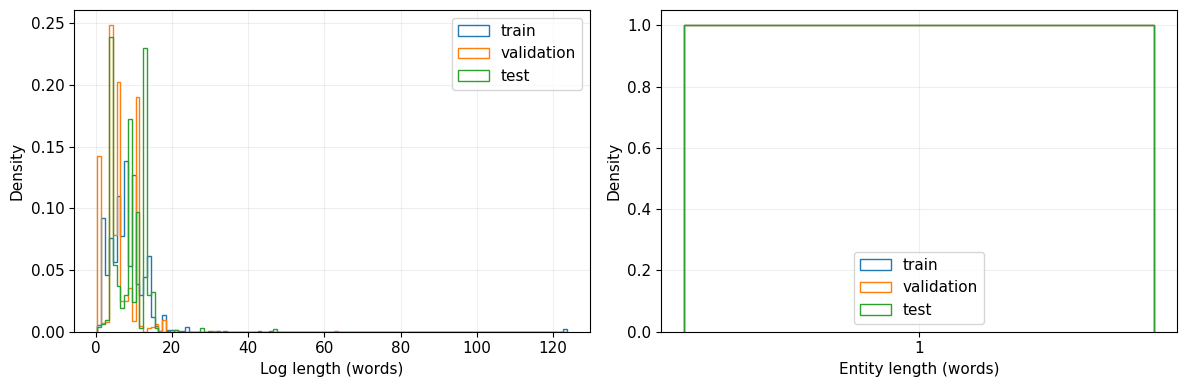

In [20]:
print(f"\n{'TYPE':<10}{'train':>12}{'validation':>12}{'test':>12}")

for entity_type in ENTITY_TYPES:
    values = [
        stats[name]["entities"][entity_type]
        for name in ("train", "validation", "test")
    ]
    print(f"{entity_type:<10}" + "".join(f"{value:>12,}" for value in values))

word_bins = np.arange(
    0.5, max(max(s["words"]) for s in stats.values()) + 1.5
)

span_bins = np.arange(
    0.5, max(max(s["spans"]) for s in stats.values()) + 1.5
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name in raw:
    axes[0].hist(
        stats[name]["words"],
        bins=word_bins,
        density=True,
        histtype="step",
        label=name,
    )
    axes[1].hist(
        stats[name]["spans"],
        bins=span_bins,
        density=True,
        histtype="step",
        label=name,
    )

axes[0].set(xlabel="Log length (words)", ylabel="Density")
axes[1].set(xlabel="Entity length (words)", ylabel="Density", xticks=[1])

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

Использованы BIO-аннотации [SDLog](https://github.com/mooselab/SDLog) и соответствующие логи с templates событий из [LogHub](https://github.com/logpai/loghub), 16 систем. Репозиторий SDLog имеет MIT лицензию; у LogHub [лицензия](https://github.com/logpai/loghub/blob/dd61d0952749ee7963bde24220d1be5ede023033/LICENSE), которая позволяет исследовательскую и академическую работу с указанием репозитория, цитированием статьи при применимости и сохранением лицензии. В статье SDLog указано, что разметка была произведена вручную двумя авторами.

Из 32 000 исходных логов исключены 2 несовпадения с `Content`, 16 494 дубликата и 25 строк с противоречивой разметкой одного текста; осталось 15 479. Разбиение сделано по шаблонам событий (чтобы не завышать метрики на test и посмотреть обобщающую способность на новых шаблонах) с фиксированным seed, без общих текстов и шаблонов между сплитами: train — 12 256, validation — 1 752, test — 1 471.

Количество сущностей на полных сплитах:

| Тип | Смысл | train | validation | test |
|---|---|---:|---:|---:|
| CONFIG | параметры конфигурации | 541 | 3 | 105 |
| ID | идентификаторы | 5 096 | 969 | 415 |
| MAC | MAC-адреса | 20 | 5 | 3 |
| NET | сетевые адреса, хосты и порты | 5 269 | 711 | 584 |
| PATH | пути | 1 642 | 146 | 54 |
| URL | URL | 99 | 5 | 17 |
| USER | имена пользователей | 616 | 5 | 120 |

Наиболее редок MAC; URL также редок, а CONFIG и USER почти отсутствуют в validation. Медианные длины логов train/validation/test — 8/6/9 слов, 95-й процентиль — 14/11/14, максимумы — 123/63/47. Все эталонные спаны в используемых файлах имеют длину 1 слово: URL или путь считается одним словом до разбиения токенизатором, а исходные теги содержат только `O` и `B-*`. Дисбаланс классов, различия шаблонов между сплитами могут сделать оценки редких классов нестабильными.


## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [21]:
from numbers import Integral


def bio_to_spans(tags):
    spans = []
    start = entity_type = None

    # Последний O закрывает сущность в конце последовательности
    for index, tag in enumerate(list(tags) + ["O"]):
        if tag == "O":
            prefix, current_type = "O", None
        else:
            if not isinstance(tag, str):
                raise ValueError(f"Invalid BIO tag: {tag!r}")

            prefix, separator, current_type = tag.partition("-")

            if prefix not in {"B", "I"} or not separator or not current_type:
                raise ValueError(f"Invalid BIO tag: {tag!r}")

        # B-, O или смена типа завершают текущую сущность
        if start is not None and (
            prefix != "I" or current_type != entity_type
        ):
            spans.append((start, index, entity_type))
            start = entity_type = None

        # I- без подходящего предшественника начинает новую сущность
        if prefix != "O" and start is None:
            start, entity_type = index, current_type

    return spans


def spans_to_bio(spans, n_words):
    if not isinstance(n_words, Integral) or n_words < 0:
        raise ValueError("n_words must be a non-negative integer")

    tags = ["O"] * n_words

    for start, end, entity_type in spans:
        if not (
            isinstance(start, Integral)
            and isinstance(end, Integral)
            and 0 <= start < end <= n_words
        ):
            raise ValueError(f"Invalid span boundaries: {(start, end)}")

        if not isinstance(entity_type, str) or not entity_type:
            raise ValueError("Entity type must be a non-empty string")

        if any(tag != "O" for tag in tags[start:end]):
            raise ValueError(
                "Overlapping spans cannot be represented in flat BIO"
            )

        tags[start] = "B-" + entity_type
        tags[start + 1:end] = ["I-" + entity_type] * (end - start - 1)

    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels = []
    seen_words = set()

    for word_id in word_ids:
        if word_id is None:
            labels.append(-100)
            continue

        if (
            not isinstance(word_id, Integral)
            or not 0 <= word_id < len(word_labels)
        ):
            raise ValueError(f"Invalid word_id: {word_id!r}")

        label = word_labels[word_id]

        if word_id not in seen_words:
            labels.append(label)
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(label, label))

        seen_words.add(word_id)

    return labels

In [22]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [23]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
# ваш код
def export_and_verify(raw):
    """Сохраняет BIO-разметку в JSONL со спанами."""
    output_dir = Path("data")
    output_dir.mkdir(exist_ok=True)
    report = {}

    for split_name, split in raw.items():
        path = output_dir / f"{split_name}_spans.jsonl"

        with path.open("w", encoding="utf-8") as stream:
            for example in split:
                tags = [
                    LABEL_NAMES[i] for i in example["ner_tags"]
                ]

                record = {
                    "id": example["id"],
                    "tokens": example["tokens"],
                    "spans": bio_to_spans(tags),
                }

                stream.write(
                    json.dumps(record, ensure_ascii=False) + "\n"
                )

        with path.open(encoding="utf-8") as stream:
            restored = [json.loads(line) for line in stream]

        assert len(restored) == len(split)

        normalized = 0

        for original, saved in zip(split, restored):
            assert original["id"] == saved["id"]
            assert original["tokens"] == saved["tokens"]

            gold = [
                LABEL_NAMES[i] for i in original["ner_tags"]
            ]

            recovered = spans_to_bio(
                saved["spans"], len(saved["tokens"])
            )

            assert bio_to_spans(recovered) == bio_to_spans(gold)
            normalized += recovered != gold

        report[split_name] = {
            "checked": len(split),
            "normalized": normalized,
        }

        print(split_name, report[split_name], path)

    return report


In [24]:
roundtrip_report = export_and_verify(raw)

train {'checked': 12256, 'normalized': 0} data/train_spans.jsonl
validation {'checked': 1752, 'normalized': 0} data/validation_spans.jsonl
test {'checked': 1471, 'normalized': 0} data/test_spans.jsonl


In [25]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/12256 [00:00<?, ? examples/s]

Map:   0%|          | 0/1752 [00:00<?, ? examples/s]

Map:   0%|          | 0/1471 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'source', 'template', 'tokens', 'ner_tags'],
        num_rows: 12256
    })
    validation: Dataset({
        features: ['id', 'source', 'template', 'tokens', 'ner_tags'],
        num_rows: 1752
    })
    test: Dataset({
        features: ['id', 'source', 'template', 'tokens', 'ner_tags'],
        num_rows: 1471
    })
})
ENTITY_TYPES ['CONFIG', 'ID', 'MAC', 'NET', 'PATH', 'URL', 'USER']
train: проверено 12152 предложений, обрезано по MAX_LENGTH 130, слов без сабвордов или за обрезкой 3514
[CLS]            None  -100
print               0  O
##F                 0  -100
##ree               0  -100
##zing              0  -100
##D                 0  -100
##is                0  -100
##play              0  -100
##L                 0  -100
##og                0  -100
##so                0  -100
##pen               0  -100
##ing               0  -100
app                 1  O
w                   2  O
##tok               2  -100
##en 

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метка ставится на первый сабворд, чтобы каждое исходное слово давало один вклад в loss независимо от количества частей (так как количество токенов, на которое делится слово не должно влиять). Спецтокены, padding и остальные сабворды получают `-100`, стандартный `ignore_index` для cross-entropy: это исключение позиции из усреднения loss (не относится к классу `O`). Сами сабворды остаются во входе и участвуют в вычислении контекста; в абляции `all_subwords` метки получают все части слова, а оценка также проводится только по первому сабворду.

В полном train (`FAST_MODE=False`, 12 256 логов, `MAX_LENGTH=128`) 130 последовательностей имеют длину 128, а 3 514 слов не получили ни одного сабворда. Условие `len(input_ids) == MAX_LENGTH` также считает последовательности, ровно достигшие лимита; слова потеряны в 104 логах, в остальных 12 152 проверено восстановление спанов. Счётчик слов объединяет обрезку и пустую токенизацию, отдельно их причины в этом выводе не разделены. Для таких слов `predict_word_tags` возвращает `O`, поэтому потерянные сущности становятся пропусками и снижают recall и F1.

При BIO -> JSONL со спанами -> BIO проверены все 15 479 очищенных логов: спаны совпали, нормализация BIO не потребовалась. Так как га этапе подготовки удалены конфликтующие аннотации и расхождения `Content`.


---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [26]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


In [27]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    # ваш код
    tag_counts = collections.defaultdict(collections.Counter)

    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            tag_counts[word][tag] += 1

    return {
        word: counts.most_common(1)[0][0]
        for word, counts in tag_counts.items()
    }


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    # ваш код
    return [tagger.get(word, "O") for word in words]


In [28]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores

In [29]:
train_tokens = [list(words) for words in data["train"]["tokens"]]
train_gold = [
    [LABEL_NAMES[label] for label in labels]
    for labels in data["train"]["ner_tags"]
]

val_tokens = [list(words) for words in data["validation"]["tokens"]]
val_gold = [
    [LABEL_NAMES[label] for label in labels]
    for labels in data["validation"]["ner_tags"]
]


In [30]:
majority_tagger = fit_majority_tagger(train_tokens, train_gold)
majority_pred = [
    predict_majority(majority_tagger, words)
    for words in val_tokens
]

baseline["majority"] = entity_scores(val_gold, majority_pred)


In [31]:
set_seed(SEED)
random_head_model = make_model()

random_head_pred = predict_word_tags(random_head_model, val_tokens)
baseline["random_head"] = entity_scores(val_gold, random_head_pred)

del random_head_model


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

In [32]:
print(
    f"{'Baseline':<16}{'F1 micro':>12}{'F1 macro':>12}"
    f"{'Precision':>12}{'Recall':>12}"
)

for name in ("majority", "random_head"):
    scores = baseline[name]
    print(
        f"{name:<16}{scores['f1_micro']:>12.4f}"
        f"{scores['f1_macro']:>12.4f}"
        f"{scores['precision']:>12.4f}{scores['recall']:>12.4f}"
    )


Baseline            F1 micro    F1 macro   Precision      Recall
majority              0.2066      0.1950      0.9072      0.1166
random_head           0.2134      0.1061      0.1276      0.6524


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

Словарный бейзлайн на всём validation: F1 micro 0.2066 и macro 0.1950, precision 0.9072 и recall 0.1166. Он распознаёт некоторые уже встречавшиеся значения (на тех же словах вставляет самый часто встречаемый тег), но на новых идентификаторах, адресах и тд не учитывает контекст и ошибается. Precision высокий, но большая часть сущностей пропущена; разбиение по шаблонам ограничивает повторение знакомых контекстов.

Энкодер со случайной головой: F1 micro 0.2134, macro 0.1061, precision 0.1276 и recall 0.6524. F1 здесь не близок к нулю, но precision низкий: много ложных срабатываний. Голова инициализирована случайными весами и не обучалась сопоставлять признаки предобученного энкодера с BIO-тегами.



---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [33]:
LR = 3e-5
BATCH_SIZE = 32
WARMUP_FRACTION = 0.1
WEIGHT_DECAY = 0.01


In [34]:
def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    # ваш код
    model.requires_grad_(True)
    if freeze_encoder:
        model.base_model.requires_grad_(False)

    steps_per_epoch = math.ceil(len(train_ds) / batch_size)
    total_steps = math.ceil(epochs * steps_per_epoch)
    log_steps = max(1, total_steps // 10)
    use_cuda = device.type == "cuda"

    args = TrainingArguments(
        output_dir=str(out_dir),
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        optim="adamw_torch",
        lr_scheduler_type="linear",
        warmup_steps=WARMUP_FRACTION,
        weight_decay=WEIGHT_DECAY,
        fp16=use_cuda,
        eval_strategy="steps",
        eval_steps=log_steps,
        prediction_loss_only=True,
        logging_strategy="steps",
        logging_steps=log_steps,
        save_strategy="no",
        report_to="none",
        seed=SEED,
    )

    collator = DataCollatorForTokenClassification(
        tokenizer=tok,
        pad_to_multiple_of=8 if use_cuda else None,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=collator,
        processing_class=tok,
    )

    if use_cuda:
        torch.cuda.synchronize()
    start = time.perf_counter()

    trainer.train()

    if use_cuda:
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start

    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '0.8979', 'grad_norm': '1.069', 'learning_rate': '2.87e-05', 'epoch': '0.2977'}
{'eval_loss': '0.06174', 'eval_runtime': '3.07', 'eval_samples_per_second': '570.7', 'eval_steps_per_second': '17.92', 'epoch': '0.2977'}
{'loss': '0.02651', 'grad_norm': '0.02067', 'learning_rate': '2.684e-05', 'epoch': '0.5953'}
{'eval_loss': '0.04976', 'eval_runtime': '2.191', 'eval_samples_per_second': '799.5', 'eval_steps_per_second': '25.1', 'epoch': '0.5953'}
{'loss': '0.01657', 'grad_norm': '0.4342', 'learning_rate': '2.353e-05', 'epoch': '0.893'}
{'eval_loss': '0.04501', 'eval_runtime': '2.313', 'eval_samples_per_second': '757.3', 'eval_steps_per_second': '23.77', 'epoch': '0.893'}
{'loss': '0.008537', 'grad_norm': '0.9272', 'learning_rate': '2.022e-05', 'epoch': '1.191'}
{'eval_loss': '0.04578', 'eval_runtime': '2.139', 'eval_samples_per_second': '819', 'eval_steps_per_second': '25.71', 'epoch': '1.191'}
{'loss': '0.005115', 'grad_norm': '0.7957', 'learning_rate': '1.691e-05', 'epoch': '1

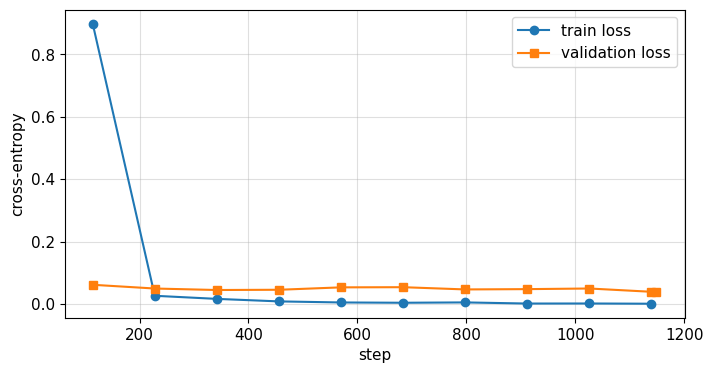

In [35]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Использованы AdamW, learning rate `3e-5`, batch size 32, линейное уменьшение learning rate, warmup на 10% шагов, weight decay 0.01 и FP16 на CUDA. Небольшой learning rate подходит для дообучения BERT-base без резкого изменения предобученных весов, batch 32 укладывается в память T4, warmup смягчает начало обучения новой головы, а weight decay ограничивает рост весов. В `FAST_MODE` выполняется 1 эпоха на 2 000 логах, в полном режиме 3 эпохи на всём train. Я подбором гиперпараметров не занимался, взял, примерно, стандарнтые значения, менял только leraning rate (от 1e-4 до 1e-5).

В полном прогоне три эпохи на 12 256 логах заняли 250.7 с на Tesla T4. Train loss по интервалам снизился с 0.8979 до 0.001084; validation loss - с 0.06174 до 0.03936. После первой эпохи validation loss колебался, но минимум 0.03930 был около конца третьей эпохи. Устойчивого роста validation loss нет, поэтому явного переобучения по этой кривой нет; пользу дополнительных эпох нужно проверять по validation F1, но польза дополнительных эпох сомнительна, так как loss вышел на плато.


## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [36]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    # ваш код
    n_correct = n_gold = n_pred = 0

    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for gold_tag, pred_tag in zip(gold_tags, pred_tags, strict=True):
            n_gold += gold_tag != "O"
            n_pred += pred_tag != "O"
            n_correct += gold_tag == pred_tag and gold_tag != "O"

    denominator = n_gold + n_pred
    return 2 * n_correct / denominator if denominator else 0.0

In [37]:
def ner_metrics(gold, pred):
    """Считает метрики по словам и сущностям и отчёт по типам сущностей."""
    report = classification_report(
        gold, pred, output_dict=True, zero_division=0
    )

    scores = entity_scores(gold, pred)
    scores["token_f1"] = token_f1(gold, pred)
    scores["per_type"] = {
        entity_type: report[entity_type]
        for entity_type in ENTITY_TYPES
        if entity_type in report
    }

    return scores


In [38]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1

In [39]:
val_pred = predict_word_tags(model, val_tokens, batch_size=BATCH_SIZE)
validation_metrics = ner_metrics(val_gold, val_pred)


In [40]:
test_tokens = [list(words) for words in data["test"]["tokens"]]
test_gold = [
    [LABEL_NAMES[label] for label in labels]
    for labels in data["test"]["ner_tags"]
]

test_pred = predict_word_tags(model, test_tokens, batch_size=BATCH_SIZE)
final = ner_metrics(test_gold, test_pred)


In [41]:
for name, gold, pred in (
    ("validation", val_gold, val_pred),
    ("test", test_gold, test_pred),
):
    print(name)
    print(classification_report(
        gold, pred, digits=4, zero_division=0
    ))
    print(f"Token F1: {token_f1(gold, pred):.4f}")


validation
              precision    recall  f1-score   support

      CONFIG     0.6667    0.6667    0.6667         3
          ID     0.9902    0.9412    0.9651       969
         MAC     1.0000    1.0000    1.0000         5
         NET     0.9986    0.9944    0.9965       711
        PATH     0.9924    0.8973    0.9424       146
         URL     0.7143    1.0000    0.8333         5
        USER     1.0000    1.0000    1.0000         5

   micro avg     0.9921    0.9582    0.9749      1844
   macro avg     0.9089    0.9285    0.9149      1844
weighted avg     0.9924    0.9582    0.9747      1844

Token F1: 0.9749
test
              precision    recall  f1-score   support

      CONFIG     0.9891    0.8667    0.9239       105
          ID     0.9653    0.9373    0.9511       415
         MAC     1.0000    1.0000    1.0000         3
         NET     0.7035    0.9914    0.8230       584
        PATH     0.7067    0.9815    0.8217        54
         URL     1.0000    0.2353    0.3810  

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

На всём validation entity F1 micro 0.9749 и macro 0.9149, на test — micro 0.8774 и macro 0.8399. На test хуже всего URL: F1 0.3810 при support 17, распознаны 4 из 17 сущностей. В train всего 99 URL, их форматы разнообразны, а длинные значения сильно дробятся токенизатором; это может мешать переносу на новые шаблоны. MAC имеет F1 1.0, но support всего 3, поэтому надёжно оценить этот тип нельзя. На validation самый низкий F1 у CONFIG — 0.6667 при support 3.

Micro F1 суммирует срабатывания всех сущностей, поэтому в нём преобладают частые ID и NET; macro усредняет F1 семи типов с одинаковым весом. На test низкий F1 URL сильнее снижает macro; F1 частых NET тоже ниже, чем на validation: 0.8230 против 0.9965. Токенный F1 совпал с entity F1: 0.9749 на validation и 0.8774 на test, поскольку эталонные сущности однословные и предсказания не дали разницы между этими критериями. В общем случае токенный F1 может засчитывать верные части длинного спана, тогда как entity F1 требует точных границ и типа; для извлечения целых сущностей пользователю обычно ближе entity F1, а для анонимизации особенно важен также recall.



---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [42]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    # ваш код
    gold_spans = [tuple(span) for span in gold_spans]
    pred_spans = [tuple(span) for span in pred_spans]
    result = []

    for gold_span in gold_spans:
        if gold_span in pred_spans:
            result.append(("correct", gold_span, gold_span))
            continue

        overlapping = [
            span for span in pred_spans
            if gold_span[0] < span[1] and span[0] < gold_span[1]
        ]

        if not overlapping:
            result.append(("missed", gold_span, None))
            continue

        same_type = [
            span for span in overlapping
            if span[2] == gold_span[2]
        ]
        candidates = same_type or overlapping
        match = max(
            candidates,
            key=lambda span: (
                min(gold_span[1], span[1]) - max(gold_span[0], span[0])
            ),
        )
        category = "boundary" if same_type else "type"
        result.append((category, gold_span, match))

    for pred_span in pred_spans:
        if not any(
            pred_span[0] < span[1] and span[0] < pred_span[1]
            for span in gold_spans
        ):
            result.append(("spurious", None, pred_span))

    return result

In [43]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров

In [44]:
def analyze_errors(tokens_list, gold_tags_list, pred_tags_list):
    """Считает категории ошибок, их доли и сохраняет до пяти примеров каждой категории."""
    counts = collections.Counter({
        category: 0 for category in ERROR_CATEGORIES
    })
    examples = {
        category: []
        for category in ERROR_CATEGORIES
        if category != "correct"
    }

    for words, gold_tags, pred_tags in zip(
        tokens_list, gold_tags_list, pred_tags_list, strict=True
    ):
        results = categorize_errors(
            bio_to_spans(gold_tags),
            bio_to_spans(pred_tags),
        )

        for category, gold_span, pred_span in results:
            counts[category] += 1

            if category != "correct" and len(examples[category]) < 5:
                examples[category].append({
                    "tokens": words,
                    "gold_span": gold_span,
                    "pred_span": pred_span,
                })

    n_errors = sum(counts.values()) - counts["correct"]
    shares = {
        category: counts[category] / n_errors if n_errors else 0.0
        for category in examples
    }

    return dict(counts), shares, examples


def show_error_examples(examples):
    """Показывает сохранённые ошибки с текстом лога и сравниваемых спанов."""
    for category, group in examples.items():
        for example in group:
            words = example["tokens"]
            print("\nКатегория:", category)
            print("Текст:", " ".join(words))

            for title, span in (
                ("Истина", example["gold_span"]),
                ("Прогноз", example["pred_span"]),
            ):
                text = (
                    None if span is None
                    else " ".join(words[span[0]:span[1]])
                )
                print(f"{title}: {span}; текст: {text}")


In [45]:
errors, error_shares, error_examples = analyze_errors(
    val_tokens, val_gold, val_pred
)


In [46]:
print(f"{'Category':<12}{'Count':>10}{'Share of errors':>20}")

for category in ERROR_CATEGORIES:
    share = "—" if category == "correct" else f"{error_shares[category]:.1%}"
    print(f"{category:<12}{errors[category]:>10,}{share:>20}")

show_error_examples(error_examples)


Category         Count     Share of errors
correct          1,767                   —
boundary             0                0.0%
type                 1                1.1%
missed              76               84.4%
spurious            13               14.4%

Категория: type
Текст: 00000009@2016/9/27:20:40:53.744 CSI Transaction @0x47e9e0 initialized for deployment engine {d16d444c-56d8-11d5-882d-0080c847b195} with flags 00000002 and client id [10]"TI6.0_0:0/"
Истина: (8, 9, 'ID'); текст: {d16d444c-56d8-11d5-882d-0080c847b195}
Прогноз: (8, 9, 'PATH'); текст: {d16d444c-56d8-11d5-882d-0080c847b195}

Категория: missed
Текст: ciod: LOGIN chdir(/p/gb2/glosli/8M_5000K/t800) failed: No such file or directory
Истина: (2, 3, 'PATH'); текст: chdir(/p/gb2/glosli/8M_5000K/t800)
Прогноз: None; текст: None

Категория: missed
Текст: ciod: LOGIN chdir(pwd) failed: No such file or directory
Истина: (2, 3, 'PATH'); текст: chdir(pwd)
Прогноз: None; текст: None

Категория: missed
Текст: ciod: LOGIN chdir(/

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

На validation самая частая ошибка — `missed`: 76, или 84.4% всех 90 ошибок. `spurious` — 13 (14.4%), `type` — 1 (1.1%), `boundary` — 0; правильных спанов — 1 767. В показанных пропусках повторяется `chdir(...)`: пути внутри вызова функции не выделены как PATH. Ошибка типа — идентификатор в фигурных скобках как PATH вместо ID. Лишние спаны — значения `bglio559`, `bglio344` и подобные, предсказанные как ID. Ошибок границ нет, так как сущности в датасете однословные.

Разметку `bglio*` стоит проверить: значения похожи на имена хостов, но в эталоне не выделены. По этим примерам нельзя утверждать, что разметка ошибочна. Для сокращения пропусков я бы добавил в train проверенные примеры путей внутри `chdir(...)` и других нестандартных форматов, затем сравнил F1 по типам на том же validation.



## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [47]:
ABLATION = ['freeze', 'all_subwords']   # 'freeze' или 'all_subwords'
ablation = {}   # ваш код

In [48]:
set_seed(SEED)
freeze_model = make_model()


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

In [49]:
freeze_history, freeze_seconds = train_ner(
    freeze_model,
    tokenized["train"],
    tokenized["validation"],
    epochs=EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    freeze_encoder=True,
    out_dir="runs/freeze",
)
RUN_TIMES["train_freeze_sec"] = freeze_seconds


{'loss': '2.932', 'grad_norm': '8.435', 'learning_rate': '2.87e-05', 'epoch': '0.2977'}
{'eval_loss': '2.598', 'eval_runtime': '2.046', 'eval_samples_per_second': '856.1', 'eval_steps_per_second': '26.88', 'epoch': '0.2977'}
{'loss': '2.406', 'grad_norm': '7.945', 'learning_rate': '2.684e-05', 'epoch': '0.5953'}
{'eval_loss': '2.026', 'eval_runtime': '2.15', 'eval_samples_per_second': '815', 'eval_steps_per_second': '25.58', 'epoch': '0.5953'}
{'loss': '1.869', 'grad_norm': '6.694', 'learning_rate': '2.353e-05', 'epoch': '0.893'}
{'eval_loss': '1.583', 'eval_runtime': '2.189', 'eval_samples_per_second': '800.5', 'eval_steps_per_second': '25.13', 'epoch': '0.893'}
{'loss': '1.465', 'grad_norm': '5.745', 'learning_rate': '2.022e-05', 'epoch': '1.191'}
{'eval_loss': '1.259', 'eval_runtime': '2.133', 'eval_samples_per_second': '821.3', 'eval_steps_per_second': '25.78', 'epoch': '1.191'}
{'loss': '1.178', 'grad_norm': '4.699', 'learning_rate': '1.691e-05', 'epoch': '1.488'}
{'eval_loss': '1

In [50]:
freeze_val_pred = predict_word_tags(
    freeze_model, val_tokens, batch_size=BATCH_SIZE
)
freeze_validation_metrics = ner_metrics(val_gold, freeze_val_pred)


In [51]:
all_subwords_data = DatasetDict({
    name: data[name].map(
        tokenize_and_align,
        batched=True,
        remove_columns=data[name].column_names,
        fn_kwargs={"label_all_subwords": True},
    )
    for name in ("train", "validation")
})

set_seed(SEED)
all_subwords_model = make_model()


Map:   0%|          | 0/12256 [00:00<?, ? examples/s]

Map:   0%|          | 0/1752 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

In [52]:
all_subwords_history, all_subwords_seconds = train_ner(
    all_subwords_model,
    all_subwords_data["train"],
    all_subwords_data["validation"],
    epochs=EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    out_dir="runs/all_subwords",
)
RUN_TIMES["train_all_subwords_sec"] = all_subwords_seconds


{'loss': '1.1', 'grad_norm': '1.903', 'learning_rate': '2.87e-05', 'epoch': '0.2977'}
{'eval_loss': '0.4421', 'eval_runtime': '2.113', 'eval_samples_per_second': '829.1', 'eval_steps_per_second': '26.03', 'epoch': '0.2977'}
{'loss': '0.06537', 'grad_norm': '0.6453', 'learning_rate': '2.684e-05', 'epoch': '0.5953'}
{'eval_loss': '0.258', 'eval_runtime': '2.092', 'eval_samples_per_second': '837.5', 'eval_steps_per_second': '26.29', 'epoch': '0.5953'}
{'loss': '0.04843', 'grad_norm': '1.053', 'learning_rate': '2.353e-05', 'epoch': '0.893'}
{'eval_loss': '0.2231', 'eval_runtime': '2.04', 'eval_samples_per_second': '858.9', 'eval_steps_per_second': '26.96', 'epoch': '0.893'}
{'loss': '0.03278', 'grad_norm': '3.228', 'learning_rate': '2.022e-05', 'epoch': '1.191'}
{'eval_loss': '0.2118', 'eval_runtime': '2.067', 'eval_samples_per_second': '847.6', 'eval_steps_per_second': '26.61', 'epoch': '1.191'}
{'loss': '0.016', 'grad_norm': '0.2105', 'learning_rate': '1.691e-05', 'epoch': '1.488'}
{'eva

In [53]:
all_subwords_pred = predict_word_tags(
    all_subwords_model, val_tokens, batch_size=BATCH_SIZE
)
all_subwords_metrics = ner_metrics(val_gold, all_subwords_pred)


In [54]:
ablation = {
    "setting": ABLATION,
    "split": "validation",
    "config": {
        "epochs": EPOCHS,
        "learning_rate": LR,
        "batch_size": BATCH_SIZE,
        "warmup_fraction": WARMUP_FRACTION,
        "weight_decay": WEIGHT_DECAY,
        "max_length": MAX_LENGTH,
        "seed": SEED,
    },
    "full": {
        "freeze_encoder": False,
        "label_all_subwords": False,
        "metrics": validation_metrics,
        "train_time_sec": RUN_TIMES["train_main_sec"],
        "trainable_params": sum(
            p.numel() for p in model.parameters() if p.requires_grad
        ),
    },
    "freeze": {
        "freeze_encoder": True,
        "label_all_subwords": False,
        "metrics": freeze_validation_metrics,
        "train_time_sec": freeze_seconds,
        "trainable_params": sum(
            p.numel() for p in freeze_model.parameters() if p.requires_grad
        ),
    },
}

ablation["all_subwords"] = {
    "freeze_encoder": False,
    "label_all_subwords": True,
    "metrics": all_subwords_metrics,
    "train_time_sec": all_subwords_seconds,
    "trainable_params": sum(
        p.numel() for p in all_subwords_model.parameters() if p.requires_grad
    ),
}

print(
    f"{'Variant':<16}{'F1 micro':>12}{'F1 macro':>12}"
    f"{'Train sec':>12}{'Trainable params':>20}"
)

for name in ("full", "freeze", "all_subwords"):
    result = ablation[name]
    print(
        f"{name:<16}{result['metrics']['f1_micro']:>12.4f}"
        f"{result['metrics']['f1_macro']:>12.4f}"
        f"{result['train_time_sec']:>12.1f}"
        f"{result['trainable_params']:>20,}"
    )

del freeze_model, all_subwords_model


Variant             F1 micro    F1 macro   Train sec    Trainable params
full                  0.9749      0.9149       250.7         107,731,215
freeze                0.0000      0.0000        91.4              11,535
all_subwords          0.8302      0.4738       232.4         107,731,215


In [ ]:
FREEZE_LR = 3e-4
FREEZE_EPOCHS = 3

set_seed(SEED)
freeze_tuned_model = make_model()

freeze_tuned_history, freeze_tuned_seconds = train_ner(
    freeze_tuned_model,
    tokenized["train"],
    tokenized["validation"],
    epochs=FREEZE_EPOCHS,
    lr=FREEZE_LR,
    batch_size=BATCH_SIZE,
    freeze_encoder=True,
    out_dir="runs/freeze_lr3e4",
)

freeze_tuned_pred = predict_word_tags(
    freeze_tuned_model, val_tokens, batch_size=BATCH_SIZE
)
freeze_tuned_metrics = ner_metrics(val_gold, freeze_tuned_pred)

print("Теги:", collections.Counter(
    tag for sentence in freeze_tuned_pred for tag in sentence
))
for name in ("f1_micro", "f1_macro", "precision", "recall", "token_f1"):
    print(f"{name}: {freeze_tuned_metrics[name]:.4f}")
print(f"Время: {freeze_tuned_seconds:.1f} с")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '2.161', 'grad_norm': '3.037', 'learning_rate': '0.000287', 'epoch': '0.2977'}
{'eval_loss': '0.7694', 'eval_runtime': '2.037', 'eval_samples_per_second': '860.2', 'eval_steps_per_second': '27', 'epoch': '0.2977'}
{'loss': '0.3889', 'grad_norm': '0.738', 'learning_rate': '0.0002684', 'epoch': '0.5953'}
{'eval_loss': '0.2125', 'eval_runtime': '2.156', 'eval_samples_per_second': '812.7', 'eval_steps_per_second': '25.51', 'epoch': '0.5953'}
{'loss': '0.2456', 'grad_norm': '0.4138', 'learning_rate': '0.0002353', 'epoch': '0.893'}
{'eval_loss': '0.1785', 'eval_runtime': '2.052', 'eval_samples_per_second': '853.8', 'eval_steps_per_second': '26.8', 'epoch': '0.893'}
{'loss': '0.2069', 'grad_norm': '0.2763', 'learning_rate': '0.0002022', 'epoch': '1.191'}
{'eval_loss': '0.1606', 'eval_runtime': '2.053', 'eval_samples_per_second': '853.5', 'eval_steps_per_second': '26.79', 'epoch': '1.191'}
{'loss': '0.1904', 'grad_norm': '0.2448', 'learning_rate': '0.0001691', 'epoch': '1.488'}
{'eval

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

Полное дообучение: validation F1 micro 0.9749 и macro 0.9149 за 250.7 с, обучаемых параметров 107 731 215. При замороженном энкодере и исходном LR `3e-5` F1 micro и macro равны 0, время — 91.4 с, обучаемых параметров 11 535 - только голова. Loss снижался, но правильных сущностей на validation не было; это согласуется с недообучением головы при выбранном LR за три эпохи.

При увеличении LR головы до `3e-4` на тех же данных и за те же три эпохи F1 micro вырос до 0.9105, macro — до 0.3964; время в сохранённых запусках — 87.0 с. В новом прогнозе есть только ID, NET и PATH; F1 остальных четырёх типов равен 0, поэтому macro заметно ниже micro. Но результат все равно не дотягивает до результата при дообучении всей модели. Это согласуется с тем, что корпус текстов, на которых был обучен энкодер, отличается от логов.

`all_subwords`: F1 micro 0.8302, macro 0.4738 за 232.4 с - ниже полного дообучения. Метки всех сабвордов увеличивают вклад сильно раздробленных слов в loss и добавляют `I-*` на продолжениях, хотя оценка остаётся по первому сабворду. Токенный F1 0.8855 выше entity F1 0.8302: часть слов размечена верно, но целые спаны не совпадают. 

Следующим шагом я бы повторил сравнение с несколькими seed, подобрал LR для головы и разобрал ошибки границ в `all_subwords`.



## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

- В полном прогоне BERT-base после трёх эпох имеет F1 micro/macro 0.9749/0.9149 на validation и 0.8774/0.8399 на test.
- Словарный бейзлайн на validation даёт F1 micro 0.2066, поэтому дообучение заметно улучшило качество на новых шаблонах.
- Исходный `freeze` с LR `3e-5` дал F1 0, но увеличение LR головы до `3e-4` повысило validation F1 micro/macro до 0.9105/0.3964.
- Разметка всех сабвордов ухудшила validation F1 micro/macro до 0.8302/0.4738.
- На test хуже всего URL: F1 0.3810, recall 0.2353, то есть распознаны только 4 из 17 сущностей; у NET и PATH низкий precision — 0.7035 и 0.7067, поэтому для этих типов проблема в большом количестве ложных срабатываний.
- На validation основная категория ошибок — 76 пропусков (missed), это 84.4% всех ошибок; лишних спанов — 13, ошибок типа — 1, ошибок границ нет.
- Ограничения — один seed, несбалансированные типы, однословная разметка и обрезка длинных логов.
- Далее я бы проверил спорную разметку, добавил разнообразные примеры проблемных форматов и повторил сравнения с несколькими seed.




### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [57]:
ARTIFACTS.mkdir(parents=True, exist_ok=True)

error_analysis = {
    "split": "validation",
    "counts": errors,
    "shares_among_errors": error_shares,
    "examples": error_examples,
}

error_analysis_path = ARTIFACTS / "error_analysis.json"
error_analysis_path.write_text(
    json.dumps(error_analysis, ensure_ascii=False, indent=2, allow_nan=False),
    encoding="utf-8",
)
print(error_analysis_path)


artifacts/error_analysis.json


In [58]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "google-bert/bert-base-cased", "revision": "cd5ef92a9fb2f889e972770a36d4ed042daf221e", "dataset": "mooselab/SDLog/main", "classes": ["CONFIG", "ID", "MAC", "NET", "PATH", "URL", "USER"], "n_train": 12256, "n_val": 1752, "n_test": 1471, "params_total": 107731215, "ablation": {"setting": ["freeze", "all_subwords"], "split": "validation", "config": {"epochs": 3, "learning_rate": 3e-05, "batch_size": 32, "warmup_fraction": 0.1, "weight_decay": 0.01, "max_length": 128, "seed": 0}, "full": {"freeze_encoder": false, "label_all_subwords": false, "metrics": {"f1_micro": 0.9748
final F1 micro 0.8774


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [59]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

Бонус 6.1 не выполнялся и не включён в `BONUS_TASKS`: новые примеры вручную не размечались. Поэтому число добавленных примеров, затраченное на разметку время и изменение метрик не измерялись; собственного опыта разрешения неоднозначностей разметки в этом эксперименте нет.


## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [60]:
import gc

LARGE_MODEL_ID = "google-bert/bert-large-cased"
LARGE_REVISION = "06fa25dc1b6e034e91607fd67c247051ccaeff65"

COMPARISON_BATCH_SIZE = 1

BENCHMARK_WARMUP = 5
BENCHMARK_RUNS = 20
COMPILE_F1_TOLERANCE = 0.005

bonus_results = {}


In [61]:
def synchronize_device(dev):
    """Ожидает завершения вычислений."""
    if dev.type == "cuda":
        torch.cuda.synchronize(dev)
    elif dev.type == "mps":
        torch.mps.synchronize()


def clear_model_cache():
    """Освобождает неиспользуемые объекты и кеш gpu."""
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()


def timed_call(function, *args, **kwargs):
    """Измеряет время вызова функции с ожиданием gpu."""
    synchronize_device(device)
    start = time.perf_counter()
    result = function(*args, **kwargs)
    synchronize_device(device)
    return result, time.perf_counter() - start


def model_size(network):
    """Возвращает число параметров, память и тип данных модели."""
    return {
        "params_total": sum(p.numel() for p in network.parameters()),
        "weights_mb": sum(
            p.numel() * p.element_size() for p in network.parameters()
        ) / 2**20,
        "dtype": str(next(network.parameters()).dtype),
    }


def save_bonus_results(results):
    ARTIFACTS.mkdir(parents=True, exist_ok=True)
    payload = {
        "model": MODEL_ID,
        "revision": REVISION,
        "dataset": DATASET_ID,
        "dataset_config": DATASET_CONFIG,
        "dataset_revisions": {
            "sdlog": SDLOG_REVISION,
            "loghub": LOGHUB_REVISION,
        },
        "device": DEVICE_NAME,
        "fast_mode": FAST_MODE,
        "experiments": results,
    }
    path = ARTIFACTS / "bonus_metrics.json"
    path.write_text(
        json.dumps(json_ready(payload), ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )
    return path


def show_model_comparison(results):
    print(
        f"{'Model':<16}{'F1 micro':>12}{'Train sec':>12}"
        f"{'ms / log':>12}{'Params, M':>12}{'Weights MB':>14}"
    )
    for name, result in results.items():
        print(
            f"{name:<16}{result['metrics']['f1_micro']:>12.4f}"
            f"{result['train_time_sec']:>12.1f}"
            f"{result['inference_ms_per_log']:>12.2f}"
            f"{result['size']['params_total'] / 1e6:>12.1f}"
            f"{result['size']['weights_mb']:>14.1f}"
        )


In [62]:
if '6.2' in BONUS_TASKS:
    # ваш код
    comparison_data = data["validation"]
    comparison_tokens = [list(words) for words in comparison_data["tokens"]]
    comparison_gold = [
        [LABEL_NAMES[label] for label in labels]
        for labels in comparison_data["ner_tags"]
    ]
    bonus_results["6.2"] = {
        "split": "validation",
        "n_evaluation": len(comparison_data),
        "sample_ids": list(comparison_data["id"]),
        "inference_batch_size": COMPARISON_BATCH_SIZE,
        "training_protocol": {
            "n_train": len(data["train"]),
            "epochs": EPOCHS,
            "learning_rate": LR,
            "batch_size": BATCH_SIZE,
            "warmup_fraction": WARMUP_FRACTION,
            "weight_decay": WEIGHT_DECAY,
            "max_length": MAX_LENGTH,
            "seed": SEED,
        },
        "models": {},
    }


In [64]:
if '6.2' in BONUS_TASKS:
    predict_word_tags(
        model, comparison_tokens[:1], batch_size=COMPARISON_BATCH_SIZE
    )
    comparison_base_pred, base_inference_seconds = timed_call(
        predict_word_tags, model, comparison_tokens,
        batch_size=COMPARISON_BATCH_SIZE,
    )
    bonus_results["6.2"]["models"]["bert_base"] = {
        "model": MODEL_ID,
        "revision": REVISION,
        "mode": "fine_tuned",
        "metrics": ner_metrics(comparison_gold, comparison_base_pred),
        "train_time_sec": RUN_TIMES["train_main_sec"],
        "inference_sec": base_inference_seconds,
        "inference_ms_per_log": 1000 * base_inference_seconds / len(comparison_tokens),
        "size": model_size(model),
    }
    save_bonus_results(bonus_results)

    model.to("cpu")
    demo_model.to("cpu")
    clear_model_cache()


In [65]:
if '6.2' in BONUS_TASKS:
    large_tokenizer = AutoTokenizer.from_pretrained(
        LARGE_MODEL_ID, revision=LARGE_REVISION, use_fast=True
    )
    large_tokenized = DatasetDict({
        name: data[name].map(
            tokenize_and_align,
            batched=True,
            remove_columns=data[name].column_names,
            fn_kwargs={"tok": large_tokenizer},
        )
        for name in ("train", "validation")
    })

    set_seed(SEED)
    large_model = make_model(model_id=LARGE_MODEL_ID, revision=LARGE_REVISION)
    large_model.gradient_checkpointing_enable(
        gradient_checkpointing_kwargs={"use_reentrant": False}
    )


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/12256 [00:00<?, ? examples/s]

Map:   0%|          | 0/1752 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

In [66]:
if '6.2' in BONUS_TASKS:
    large_history, large_train_seconds = train_ner(
        large_model,
        large_tokenized["train"],
        large_tokenized["validation"],
        epochs=EPOCHS,
        lr=LR,
        batch_size=BATCH_SIZE,
        tok=large_tokenizer,
        out_dir="runs/bert-large",
    )
    RUN_TIMES["train_large_sec"] = large_train_seconds


{'loss': '0.6018', 'grad_norm': '4.803', 'learning_rate': '2.87e-05', 'epoch': '0.2977'}
{'eval_loss': '0.07558', 'eval_runtime': '6.247', 'eval_samples_per_second': '280.5', 'eval_steps_per_second': '8.805', 'epoch': '0.2977'}
{'loss': '0.02178', 'grad_norm': '0.008756', 'learning_rate': '2.684e-05', 'epoch': '0.5953'}
{'eval_loss': '0.08217', 'eval_runtime': '6.267', 'eval_samples_per_second': '279.6', 'eval_steps_per_second': '8.776', 'epoch': '0.5953'}
{'loss': '0.01596', 'grad_norm': '0.2447', 'learning_rate': '2.353e-05', 'epoch': '0.893'}
{'eval_loss': '0.04142', 'eval_runtime': '6.208', 'eval_samples_per_second': '282.2', 'eval_steps_per_second': '8.86', 'epoch': '0.893'}
{'loss': '0.006679', 'grad_norm': '2.921', 'learning_rate': '2.022e-05', 'epoch': '1.191'}
{'eval_loss': '0.04127', 'eval_runtime': '6.253', 'eval_samples_per_second': '280.2', 'eval_steps_per_second': '8.795', 'epoch': '1.191'}
{'loss': '0.00455', 'grad_norm': '1.172', 'learning_rate': '1.691e-05', 'epoch': '

In [67]:
if '6.2' in BONUS_TASKS:
    predict_word_tags(
        large_model, comparison_tokens[:1], tok=large_tokenizer,
        batch_size=COMPARISON_BATCH_SIZE,
    )
    comparison_large_pred, large_inference_seconds = timed_call(
        predict_word_tags, large_model, comparison_tokens,
        tok=large_tokenizer, batch_size=COMPARISON_BATCH_SIZE,
    )
    bonus_results["6.2"]["models"]["bert_large"] = {
        "model": LARGE_MODEL_ID,
        "revision": LARGE_REVISION,
        "mode": "fine_tuned",
        "gradient_checkpointing": True,
        "metrics": ner_metrics(comparison_gold, comparison_large_pred),
        "train_time_sec": large_train_seconds,
        "inference_sec": large_inference_seconds,
        "inference_ms_per_log": (
            1000 * large_inference_seconds / len(comparison_tokens)
        ),
        "size": model_size(large_model),
    }
    save_bonus_results(bonus_results)
    show_model_comparison(bonus_results["6.2"]["models"])

    large_test_pred = predict_word_tags(
        large_model, test_tokens,
        tok=large_tokenizer, batch_size=BATCH_SIZE,
    )
    print("\nBERT-large на test")
    print(classification_report(
        test_gold, large_test_pred, digits=4, zero_division=0
    ))

    del large_model
    clear_model_cache()
    model.to(device)

Model               F1 micro   Train sec    ms / log   Params, M    Weights MB
bert_base             0.9749       250.7       13.68       107.7         411.0
bert_large            0.9734       893.0       25.81       332.5        1268.6

BERT-large на test
              precision    recall  f1-score   support

      CONFIG     0.9901    0.9524    0.9709       105
          ID     0.9799    0.9398    0.9594       415
         MAC     1.0000    1.0000    1.0000         3
         NET     0.9983    0.9932    0.9957       584
        PATH     0.7313    0.9074    0.8099        54
         URL     1.0000    0.2353    0.3810        17
        USER     1.0000    0.9500    0.9744       120

   micro avg     0.9779    0.9553    0.9665      1298
   macro avg     0.9571    0.8540    0.8702      1298
weighted avg     0.9808    0.9553    0.9643      1298



**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

На validation F1 micro у BERT-large немного ниже: 0.9734 против 0.9749 у base, а macro выше: 0.9321 против 0.9149. \
На test large лучше по F1: micro 0.9665 против 0.8774, macro 0.8702 против 0.8399. Основной выигрыш — NET: 0.9957 против 0.8230; CONFIG тоже лучше — 0.9709 против 0.9239.

Обучение large — 893.0 против 250.7 с, инференс — 25.81 против 13.68 мс/лог; параметров 332.5 против 107.7 млн, память весов FP32 — 1 268.6 против 411.0 MiB. 
Честность сравнения обеспечивалась за счет одинаковых train, validation, test, seed, 3 эпохи, LR, batch size и `MAX_LENGTH`, устройство — T4

Отсюда мы получаем вывод, что большая модель показывает себя лучше по метрикам на тестовых данных.

Вопрос о том какая модель лучше, это стандратный вопрос о трейдофе между моделью, которая меньше и моделью, у которой качество выше. Если важнее скорость, потому что инференс у large в два раза выше (в высоконагруженной системе, где огромное количество логов это будет значительно), хотя прирост по метрикам на test заметный, поэтому можно сделать выбор в пользу bert_large. Для инференса эти модели не тяжелые и можно поднимать несколько инстансов, поэтому можно выбрать bert_large



## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [68]:
def shifted_tokens(tokens_list, mode, seed=SEED, typo_probability=0.15):
    """Меняет регистр или переставляет соседние буквы, сохраняя слова и позиции меток."""
    if mode not in {"lowercase", "uppercase", "typos"}:
        raise ValueError("Unknown text shift")

    rng = random.Random(seed)
    shifted = []
    for words in tokens_list:
        sentence = []
        for word in words:
            if mode == "lowercase":
                word = word.lower()
            elif mode == "uppercase":
                word = word.upper()
            elif rng.random() < typo_probability:
                positions = [
                    index for index in range(len(word) - 1)
                    if word[index].isalpha() and word[index + 1].isalpha()
                    and word[index] != word[index + 1]
                ]
                if positions:
                    index = rng.choice(positions)
                    chars = list(word)
                    chars[index], chars[index + 1] = chars[index + 1], chars[index]
                    word = "".join(chars)
            sentence.append(word)
        shifted.append(sentence)

    return shifted


In [69]:
if '6.3' in BONUS_TASKS:
    # ваш код
    shift_results = {
        "split": "validation",
        "n_evaluation": len(val_tokens),
        "seed": SEED,
        "typo_probability": 0.15,
        "variants": {
            "clean": {
                "metrics": validation_metrics,
                "changed_words": 0,
                "f1_delta": 0.0,
            },
        },
    }

    for mode in ("lowercase", "uppercase", "typos"):
        corrupted_tokens = shifted_tokens(val_tokens, mode, seed=SEED)
        corrupted_pred = predict_word_tags(
            model, corrupted_tokens, batch_size=BATCH_SIZE
        )
        scores = ner_metrics(val_gold, corrupted_pred)
        changed_words = sum(
            original != corrupted
            for original_words, corrupted_words in zip(val_tokens, corrupted_tokens, strict=True)
            for original, corrupted in zip(original_words, corrupted_words, strict=True)
        )
        shift_results["variants"][mode] = {
            "metrics": scores,
            "changed_words": changed_words,
            "f1_delta": float(scores["f1_micro"] - validation_metrics["f1_micro"]),
        }

    bonus_results["6.3"] = shift_results
    save_bonus_results(bonus_results)
    print(f"{'Shift':<14}{'F1 micro':>12}{'F1 delta':>12}{'Changed words':>16}")
    for mode, result in shift_results["variants"].items():
        print(
            f"{mode:<14}{result['metrics']['f1_micro']:>12.4f}"
            f"{result['f1_delta']:>12.4f}{result['changed_words']:>16}"
        )


Shift             F1 micro    F1 delta   Changed words
clean               0.9749      0.0000               0
lowercase           0.9704     -0.0045            3179
uppercase           0.6207     -0.3542            8395
typos               0.9421     -0.0328            1338


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

На всём validation сильнее всего мешает верхний регистр: F1 micro 0.9749 → 0.6207 (−0.3542). Нижний регистр даёт 0.9704 (−0.0045), опечатки — 0.9421 (−0.0328). BERT-cased различает регистр, поэтому uppercase меняет знакомые формы слов, WordPiece-разбиение и признаки в контексте сущностей.

Опечатки влияют слабее: для идентификаторов, адресов и путей структура значения и контекст могут быть важнее конкретного написания. Перестановка соседних букв сохраняет цифры и разделители, но всё же может менять токенизацию. Кроме того, опечатки затронули только 1 338 слов против 8 395 при uppercase, поэтому разница зависит и от масштаба порчи.



## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [70]:
@torch.inference_mode()
def benchmark_forward(network, inputs, n_warmup=5, n_runs=20):
    """Измеряет задержку прямого прохода."""
    if n_runs < 10:
        raise ValueError("At least 10 timed runs are required")

    network.eval()
    synchronize_device(device)
    start = time.perf_counter()
    for _ in range(n_warmup):
        network(**inputs)
    synchronize_device(device)
    warmup_seconds = time.perf_counter() - start

    milliseconds = []
    for _ in range(n_runs):
        synchronize_device(device)
        start = time.perf_counter()
        network(**inputs)
        synchronize_device(device)
        milliseconds.append(1000 * (time.perf_counter() - start))

    return {
        "mean_ms": float(np.mean(milliseconds)),
        "median_ms": float(np.median(milliseconds)),
        "std_ms": float(np.std(milliseconds)),
        "warmup_sec": warmup_seconds,
        "n_warmup": n_warmup,
        "n_runs": n_runs,
    }


@torch.inference_mode()
def predict_fixed_word_tags(network, tokens_list, tok=None, batch_size=BATCH_SIZE):
    """Предсказывает теги слов с постоянной длиной батчей для проверки скомпилированной модели."""
    tok = tok or tokenizer
    network.eval().to(device)
    predictions = []

    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(
            batch,
            is_split_into_words=True,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt",
        ).to(device)
        best = network(**enc).logits.argmax(-1).cpu().tolist()

        for index, words in enumerate(batch):
            tags, seen = ["O"] * len(words), set()
            for position, word_id in enumerate(enc.word_ids(index)):
                if word_id is not None and word_id not in seen:
                    tags[word_id] = network.config.id2label[best[index][position]]
                    seen.add(word_id)
            predictions.append(tags)

    return predictions


In [71]:
if '6.4' in BONUS_TASKS:
    # ваш код
    model.eval().to(device)
    benchmark_inputs = tokenizer(
        val_tokens[:BATCH_SIZE],
        is_split_into_words=True,
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH,
        return_tensors="pt",
    ).to(device)
    compiled_model = torch.compile(model, mode="default", dynamic=True)

    eager_timing = benchmark_forward(
        model, benchmark_inputs, BENCHMARK_WARMUP, BENCHMARK_RUNS
    )
    compiled_timing = benchmark_forward(
        compiled_model, benchmark_inputs, BENCHMARK_WARMUP, BENCHMARK_RUNS
    )

    with torch.inference_mode():
        eager_logits = model(**benchmark_inputs).logits
        compiled_logits = compiled_model(**benchmark_inputs).logits
        max_logit_difference = float((eager_logits - compiled_logits).abs().max().cpu())

    eager_fixed_pred = predict_fixed_word_tags(model, val_tokens)
    compiled_pred = predict_fixed_word_tags(compiled_model, val_tokens)
    eager_compile_metrics = ner_metrics(val_gold, eager_fixed_pred)
    compiled_metrics = ner_metrics(val_gold, compiled_pred)
    same_tags = sum(
        eager == compiled
        for eager_tags, compiled_tags in zip(eager_fixed_pred, compiled_pred, strict=True)
        for eager, compiled in zip(eager_tags, compiled_tags, strict=True)
    )
    n_words = sum(len(words) for words in val_tokens)

    speed_results = {
        "method": "torch.compile",
        "backend": "inductor",
        "mode": "default",
        "dynamic": True,
        "device": str(device),
        "size": model_size(model),
        "input_shapes": {name: list(value.shape) for name, value in benchmark_inputs.items()},
        "eager": {"timing": eager_timing, "metrics": eager_compile_metrics},
        "compiled": {"timing": compiled_timing, "metrics": compiled_metrics},
        "speedup": eager_timing["mean_ms"] / compiled_timing["mean_ms"],
        "max_logit_difference": max_logit_difference,
        "word_tag_agreement": same_tags / n_words if n_words else 1.0,
        "f1_tolerance": COMPILE_F1_TOLERANCE,
        "quality_preserved": bool(
            compiled_metrics["f1_micro"]
            >= eager_compile_metrics["f1_micro"] - COMPILE_F1_TOLERANCE
        ),
    }
    bonus_results["6.4"] = speed_results
    save_bonus_results(bonus_results)
    print(f"{'Variant':<14}{'Mean ms':>12}{'Std ms':>12}{'F1 micro':>12}")
    for name in ("eager", "compiled"):
        result = speed_results[name]
        print(
            f"{name:<14}{result['timing']['mean_ms']:>12.3f}"
            f"{result['timing']['std_ms']:>12.3f}"
            f"{result['metrics']['f1_micro']:>12.4f}"
        )
    print("Speedup:", round(speed_results["speedup"], 3))
    print("F1 within tolerance:", speed_results["quality_preserved"])

    del compiled_model, eager_logits, compiled_logits
    clear_model_cache()


Variant            Mean ms      Std ms    F1 micro
eager               62.746       0.664      0.9749
compiled            55.957       0.682      0.9749
Speedup: 1.121
F1 within tolerance: True


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

На Tesla T4 torch.compile уменьшил задержку с 62.746 (std=0.664) до 55.957 (std=0.682) мс. Батч 32 * 128, 5 прогревочных и 20 измеряемых запусков; время компиляции в задержку не входит. Validation F1 micro сохранился — 0.9749.
Основные вычисления идут в 12 слоях энкодера (на предыдущих у меня был вывод в каких частях больше всего параметров); выигрыш зависит от оптимизации их операций, формы батча и устройства.



## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

In [72]:
def scored_entity_spans(tags_list, probabilities_list, aggregation="mean"):
    """Сопоставляет каждому предсказанному спану среднюю или минимальную уверенность его слов."""
    if aggregation not in {"mean", "min"}:
        raise ValueError("Aggregation must be 'mean' or 'min'")

    result = []
    for tags, probabilities in zip(tags_list, probabilities_list, strict=True):
        if len(tags) != len(probabilities):
            raise ValueError("Tags and probabilities must have equal lengths")
        if any(not math.isfinite(p) or not 0 <= p <= 1 for p in probabilities):
            raise ValueError("Probabilities must be finite and between 0 and 1")

        sentence = []
        for start, end, entity_type in bio_to_spans(tags):
            values = probabilities[start:end]
            confidence = sum(values) / len(values) if aggregation == "mean" else min(values)
            sentence.append((start, end, entity_type, float(confidence)))
        result.append(sentence)

    return result


def span_precision_recall_curve(gold_tags, scored_spans):
    """Считает точную micro precision-recall кривую."""
    ranked, n_gold = [], 0
    for tags, spans in zip(gold_tags, scored_spans, strict=True):
        gold = set(bio_to_spans(tags))
        n_gold += len(gold)
        ranked.extend(
            (confidence, (start, end, entity_type) in gold)
            for start, end, entity_type, confidence in spans
        )
    ranked.sort(key=lambda item: item[0], reverse=True)

    curve = [{
        "threshold": math.nextafter(1.0, math.inf),
        "precision": 0.0,
        "recall": 0.0,
        "f1_micro": 0.0,
        "n_spans": 0,
    }]
    n_pred = n_correct = 0

    for index, (confidence, correct) in enumerate(ranked):
        n_pred += 1
        n_correct += correct
        if index + 1 < len(ranked) and ranked[index + 1][0] == confidence:
            continue

        curve.append({
            "threshold": confidence,
            "precision": n_correct / n_pred,
            "recall": n_correct / n_gold if n_gold else 0.0,
            "f1_micro": 2 * n_correct / (n_gold + n_pred) if n_gold + n_pred else 0.0,
            "n_spans": n_pred,
        })

    if curve[-1]["threshold"] != 0.0:
        curve.append({**curve[-1], "threshold": 0.0})
    return sorted(curve, key=lambda point: point["threshold"])


def filter_scored_spans(scored_spans, word_counts, threshold):
    """Отбрасывает спаны ниже порога и восстанавливает BIO-теги для всех слов."""
    return [
        spans_to_bio(
            [
                (start, end, entity_type)
                for start, end, entity_type, confidence in spans
                if confidence >= threshold
            ],
            n_words,
        )
        for spans, n_words in zip(scored_spans, word_counts, strict=True)
    ]


In [73]:
if '6.5' in BONUS_TASKS:
    # ваш код
    threshold_pred, threshold_probabilities = predict_word_tags(
        model, val_tokens, batch_size=BATCH_SIZE, return_probs=True
    )
    threshold_baseline = ner_metrics(val_gold, threshold_pred)
    word_counts = [len(tags) for tags in threshold_pred]
    threshold_results = {
        "split": "validation",
        "n_evaluation": len(val_tokens),
        "criterion": "f1_micro",
        "sweep": "all_unique_span_scores",
        "variants": {},
    }

    for aggregation in ("mean", "min"):
        scored = scored_entity_spans(
            threshold_pred, threshold_probabilities, aggregation=aggregation
        )
        curve = span_precision_recall_curve(val_gold, scored)
        best = max(curve, key=lambda point: point["f1_micro"])
        filtered_pred = filter_scored_spans(scored, word_counts, best["threshold"])
        filtered_metrics = ner_metrics(val_gold, filtered_pred)
        threshold_results["variants"][aggregation] = {
            "best_threshold": best["threshold"],
            "before": threshold_baseline,
            "after": filtered_metrics,
            "f1_gain": float(filtered_metrics["f1_micro"] - threshold_baseline["f1_micro"]),
            "curve": curve,
        }

    bonus_results["6.5"] = threshold_results
    save_bonus_results(bonus_results)
    print(f"{'Score':<12}{'Threshold':>12}{'F1 before':>12}{'F1 after':>12}{'F1 gain':>12}")
    for aggregation, result in threshold_results["variants"].items():
        print(
            f"{aggregation:<12}{result['best_threshold']:>12.6f}"
            f"{result['before']['f1_micro']:>12.4f}"
            f"{result['after']['f1_micro']:>12.4f}{result['f1_gain']:>12.4f}"
        )


Score          Threshold   F1 before    F1 after     F1 gain
mean            0.822275      0.9749      0.9779      0.0030
min             0.822275      0.9749      0.9779      0.0030


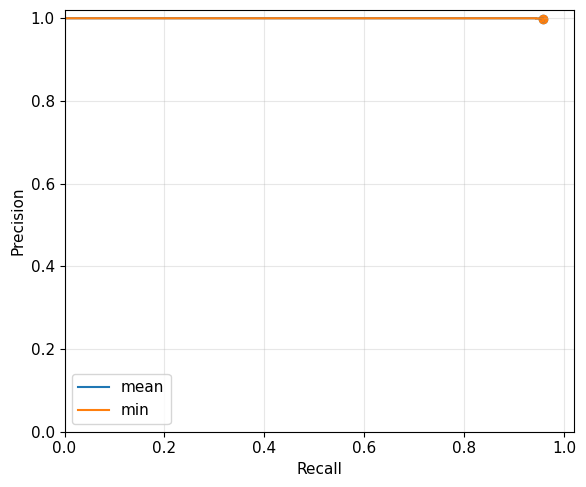

In [74]:
if '6.5' in BONUS_TASKS:
    fig, ax = plt.subplots(figsize=(6, 5))
    for aggregation, result in threshold_results["variants"].items():
        curve = result["curve"]
        ax.plot(
            [point["recall"] for point in curve],
            [point["precision"] for point in curve],
            label=aggregation,
        )
        ax.scatter(
            result["after"]["recall"], result["after"]["precision"], s=35
        )
    ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1.02), ylim=(0, 1.02))
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(ARTIFACTS / "precision_recall_thresholds.png", dpi=150)
    plt.show()


**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Лучший порог — 0.822275: F1 micro 0.9749 -> 0.9779 (+0.0030), precision 0.9921 -> 0.9989, recall снизился с 0.9582 до 0.9577.
Фильтрация удалила спаны, поэтому precision (из-за удаления ложного спана) вырос, а recall немного снизился (из-за удаления верного спана).

Средняя уверенность усредняет вероятности предсказанных тегов по словам спана: высокая уверенность одних слов может компенсировать низкую уверенность других. Минимальная берёт наименьшую вероятность, поэтому сильнее отбрасывает спаны с хотя бы одним неуверенным словом. Для однословных спанов разницы между ними нет; у меня оба способа дали одинаковые кривые и результат. Порог только удаляет готовые спаны, не добавляя пропущенные и не исправляя типы или границы, поэтому recall вырасти не может.


